In [2]:
# Standard library
import os
import sys
import time
import json
import logging
import multiprocessing
from pathlib import Path

# Scientific Python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.table import Table

# Pipeline under test -- import functions directly rather than shelling out,
# so we can time individual pieces (not just the whole CLI script).
sys.path.insert(0, "/path/to/dir/containing/build_cutouts_fast.py")
from build_cutouts_fast import _rescale_worker, build_ssl_hdf5
from SGA.SGA import get_galaxy_galaxydir, sga_data_dir

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s", stream=sys.stdout)
log = logging.getLogger("benchmark")

In [3]:
# ============================================================
# USER CONFIGURATION
# ============================================================
CATALOG_PATH = "/global/cfs/cdirs/desi/users/ioannis/SGA/2025/public/SGA2025-v1.0.fits"
REGION = "dr11-south"
DATADIR = None  # defaults to $SGA_DATA_DIR
OUTPUT_DIR = Path("/pscratch/sd/q/qshimp/Sorter/cutout_benchmark")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

N_SUBSAMPLE = 2000          # galaxies drawn for benchmarking -- large enough to
                             # amortize per-worker startup cost, small enough to
                             # run many configs quickly
WIDTH = 152
PIXSCALE = 0.262
SEED = 67

# mp values to test -- include 1 (serial baseline) and go up to at least your
# node's full core count; os.cpu_count() reports what Python sees available.
AVAILABLE_CPUS = os.cpu_count()
MP_GRID = sorted(set([1, 2, 4, 8, 16, AVAILABLE_CPUS // 2, AVAILABLE_CPUS]))
MP_GRID = [m for m in MP_GRID if m >= 1]
print(f"Detected {AVAILABLE_CPUS} CPUs available; testing mp={MP_GRID}")

# NERSC-specific: if running inside a Slurm allocation, SLURM_CPUS_PER_TASK
# is the actual quota, which can differ from os.cpu_count() (which may report
# the whole node). Worth checking both.
slurm_cpus = os.environ.get("SLURM_CPUS_PER_TASK")
if slurm_cpus:
    print(f"SLURM_CPUS_PER_TASK={slurm_cpus} (your actual allocation may be smaller than os.cpu_count())")

RESULTS_LOG_PATH = OUTPUT_DIR / "benchmark_log.csv"

Detected 256 CPUs available; testing mp=[1, 2, 4, 8, 16, 128, 256]
SLURM_CPUS_PER_TASK=256 (your actual allocation may be smaller than os.cpu_count())


In [5]:
print(f"Loading catalog: {CATALOG_PATH}")
t0 = time.perf_counter()

if CATALOG_PATH.endswith(".fits"):
    sample = Table.read(CATALOG_PATH)
else:
    sample = Table.from_pandas(pd.read_csv(CATALOG_PATH))

print(f"  {len(sample):,d} total galaxies ({time.perf_counter()-t0:.1f}s)")

rng = np.random.default_rng(SEED)
idx = rng.choice(
    len(sample),
    size=min(N_SUBSAMPLE, len(sample)),
    replace=False
)
bench_sample = sample[idx]

print(f"Benchmark subsample: {len(bench_sample):,d} galaxies")

datadir = DATADIR or sga_data_dir()

# Decode byte-string columns once
bench_sample = bench_sample.copy()
for col in ["GROUP_NAME", "SGAGROUP"]:
    if col in bench_sample.colnames:
        bench_sample[col] = [
            x.decode() if isinstance(x, (bytes, np.bytes_)) else str(x)
            for x in bench_sample[col]
        ]

# ------------------------------------------------------------
# Resolve directories separately for South and North
# ------------------------------------------------------------
print("Resolving galaxy directories by region...")
t0 = time.perf_counter()

bench_args = []
region_counts = {}
region_key = {
    'dr11-south': 1,
    'dr11-north': [2, 3]
}

for region in ['dr11-south', 'dr11-north']:
    # np.isin checks if the REGION column matches any number in our list
    region_mask = np.isin(bench_sample["REGION"], region_key[region])
    region_sample = bench_sample[region_mask]

    if len(region_sample) == 0:
        continue

    print(f"  {region}: {len(region_sample):,d} galaxies")

    _, galaxydirs = get_galaxy_galaxydir(
        region_sample,
        region=region,
        group=True,
        datadir=datadir
    )

    region_counts[region] = len(galaxydirs)

    for row, gdir in zip(region_sample, galaxydirs):
        bench_args.append(
            (
                str(row["SGAGROUP"]),
                str(row["BANDS"]),
                float(row["RA"]),
                float(row["DEC"]),
                str(gdir),
                WIDTH,
                PIXSCALE,
            )
        )

print(
    f"  Resolved {len(bench_args):,d} directories "
    f"({time.perf_counter()-t0:.1f}s)"
)

print("\nBenchmark sample by region:")
for region, count in region_counts.items():
    print(f"  {region}: {count:,d}")

print(f"Prepared {len(bench_args):,d} argument tuples for benchmarking")

Loading catalog: /global/cfs/cdirs/desi/users/ioannis/SGA/2025/public/SGA2025-v1.0.fits
2026-09-22 07:20:55,639 WARNING hdu= was not specified but multiple tables are present, reading in first available table (hdu=1)


2026-09-22 07:20:56,781 WARNING UnitsWarning: 'nanomaggies' did not parse as fits unit: At col 0, Unit 'nanomaggies' not supported by the FITS standard.  If this is meant to be a custom unit, define it with 'u.def_unit'. To have it recognized inside a file reader or other code, enable it with 'u.add_enabled_units'. For details, see https://docs.astropy.org/en/latest/units/combining_and_defining.html
2026-09-22 07:20:56,805 WARNING UnitsWarning: 'nanomaggies' did not parse as fits unit: At col 0, Unit 'nanomaggies' not supported by the FITS standard.  If this is meant to be a custom unit, define it with 'u.def_unit'. To have it recognized inside a file reader or other code, enable it with 'u.add_enabled_units'. For details, see https://docs.astropy.org/en/latest/units/combining_and_defining.html
2026-09-22 07:20:56,831 WARNING UnitsWarning: 'nanomaggies' did not parse as fits unit: At col 0, Unit 'nanomaggies' not supported by the FITS standard.  If this is meant to be a custom unit, de

2026-09-22 07:20:56,993 WARNING UnitsWarning: 'nanomaggies^(-2)' did not parse as fits unit: At col 0, Unit 'nanomaggies' not supported by the FITS standard.  If this is meant to be a custom unit, define it with 'u.def_unit'. To have it recognized inside a file reader or other code, enable it with 'u.add_enabled_units'. For details, see https://docs.astropy.org/en/latest/units/combining_and_defining.html
2026-09-22 07:20:57,017 WARNING UnitsWarning: 'nanomaggies^(-2)' did not parse as fits unit: At col 0, Unit 'nanomaggies' not supported by the FITS standard.  If this is meant to be a custom unit, define it with 'u.def_unit'. To have it recognized inside a file reader or other code, enable it with 'u.add_enabled_units'. For details, see https://docs.astropy.org/en/latest/units/combining_and_defining.html
2026-09-22 07:20:57,040 WARNING UnitsWarning: 'nanomaggies^(-2)' did not parse as fits unit: At col 0, Unit 'nanomaggies' not supported by the FITS standard.  If this is meant to be a 

2026-09-22 07:20:57,196 WARNING UnitsWarning: 'nanomaggies' did not parse as fits unit: At col 0, Unit 'nanomaggies' not supported by the FITS standard.  If this is meant to be a custom unit, define it with 'u.def_unit'. To have it recognized inside a file reader or other code, enable it with 'u.add_enabled_units'. For details, see https://docs.astropy.org/en/latest/units/combining_and_defining.html
2026-09-22 07:20:57,246 WARNING UnitsWarning: 'nanomaggies^(-2)' did not parse as fits unit: At col 0, Unit 'nanomaggies' not supported by the FITS standard.  If this is meant to be a custom unit, define it with 'u.def_unit'. To have it recognized inside a file reader or other code, enable it with 'u.add_enabled_units'. For details, see https://docs.astropy.org/en/latest/units/combining_and_defining.html
2026-09-22 07:20:57,263 WARNING UnitsWarning: 'nanomaggies^(-2)' did not parse as fits unit: At col 0, Unit 'nanomaggies' not supported by the FITS standard.  If this is meant to be a custo

  470,625 total galaxies (2.1s)
Benchmark subsample: 2,000 galaxies
Resolving galaxy directories by region...
  dr11-south: 1,620 galaxies
  dr11-north: 380 galaxies
  Resolved 2,000 directories (0.0s)

Benchmark sample by region:
  dr11-south: 1,620
  dr11-north: 380
Prepared 2,000 argument tuples for benchmarking


In [12]:
len3 = len(sample[sample['REGION'] == 3])
len2 = len(sample[sample['REGION'] == 2])
len1 = len(sample[sample['REGION'] == 1])

print(len3)
print(len2)
print(len1)
print(len(sample))
print(len3+len2+len1)

15314
75190
380121
470625
470625


In [44]:
print("\n" + "=" * 60)
print("BASELINE: single-galaxy timing (serial, small sample)")
print("=" * 60)

n_baseline = min(200, len(bench_args))
baseline_args = bench_args[:n_baseline]

times = []
edge_fracs = []
missing_paths = []

for i, a in enumerate(baseline_args):
    t0 = time.perf_counter()

    try:
        img, frac = _rescale_worker(a)

        times.append(time.perf_counter() - t0)
        edge_fracs.append(frac)

    except Exception as e:
        missing_paths.append({
            "index": i,
            "arg": a,
            "error": repr(e),
        })

        print(f"  WARNING: failed galaxy {i + 1}/{n_baseline}")
        print(f"           error: {e}")

        continue

times = np.array(times)
edge_fracs = np.array(edge_fracs)

n_success = len(times)
n_failed = len(missing_paths)

print(f"\n  Requested: {n_baseline}")
print(f"  Successful: {n_success}")
print(f"  Failed/missing: {n_failed}")

if n_success > 0:
    print(f"\n  mean:   {times.mean()*1000:.2f} ms/galaxy")
    print(f"  median: {np.median(times)*1000:.2f} ms/galaxy")
    print(f"  std:    {times.std()*1000:.2f} ms/galaxy")
    print(f"  p95:    {np.percentile(times, 95)*1000:.2f} ms/galaxy")

    print(
        f"  galaxies with edge_frac > 0: "
        f"{int(np.count_nonzero(edge_fracs > 0))}/{n_success} "
        f"(max edge_frac={edge_fracs.max():.3f})"
    )

    single_worker_rate = 1.0 / times.mean()

    print(f"\n  Implied single-worker throughput: "
          f"{single_worker_rate:.1f} galaxies/sec")

    print(
        f"  Naive full-catalog estimate "
        f"({len(sample):,d} galaxies, mp=1): "
        f"{len(sample) / single_worker_rate / 3600:.1f} hours"
    )
else:
    print("\n  No successful galaxies were processed; timing unavailable.")

# Print a compact summary of failures
if missing_paths:
    print("\n" + "-" * 60)
    print(f"MISSING/FAILED PATHS ({len(missing_paths)}):")
    print("-" * 60)

    for item in missing_paths:
        print(f"  [{item['index']}] {item['arg']}")
        print(f"       {item['error']}")


BASELINE: single-galaxy timing (serial, small sample)

  Requested: 200
  Successful: 200
  Failed/missing: 0

  mean:   151.35 ms/galaxy
  median: 139.04 ms/galaxy
  std:    47.54 ms/galaxy
  p95:    245.86 ms/galaxy
  galaxies with edge_frac > 0: 1/200 (max edge_frac=0.079)

  Implied single-worker throughput: 6.6 galaxies/sec
  Naive full-catalog estimate (470,625 galaxies, mp=1): 19.8 hours


In [45]:
def run_mp_benchmark(args_list, mp, label=""):
    """Run the actual multiprocessing.Pool path (matching build_ssl_hdf5's
    real code path exactly, not a simplified stand-in) and time it end-to-end."""
    t0 = time.perf_counter()
    edge_fracs = []
    if mp > 1:
        with multiprocessing.Pool(mp) as P:
            for img, frac in P.imap(_rescale_worker, args_list):
                edge_fracs.append(frac)
    else:
        for a in args_list:
            img, frac = _rescale_worker(a)
            edge_fracs.append(frac)
    elapsed = time.perf_counter() - t0
    rate = len(args_list) / elapsed
    return {
        "mp": mp,
        "n_galaxies": len(args_list),
        "elapsed_sec": elapsed,
        "galaxies_per_sec": rate,
        "n_edge_affected": int(np.count_nonzero(np.array(edge_fracs) > 0)),
        "label": label,
    }


print("\n" + "=" * 60)
print(f"MP SWEEP: {len(MP_GRID)} worker-count(s), {len(bench_args):,d} galaxies each")
print("=" * 60)

mp_results = []
for mp_val in MP_GRID:
    print(f"\n--- mp={mp_val} ---")
    result = run_mp_benchmark(bench_args, mp_val, label=f"mp_sweep")
    mp_results.append(result)
    print(f"  {result['elapsed_sec']:.1f}s total  |  "
         f"{result['galaxies_per_sec']:.1f} galaxies/sec  |  "
         f"est. full catalog: {len(sample) / result['galaxies_per_sec'] / 3600:.2f}h")

mp_df = pd.DataFrame(mp_results)
mp_df["speedup_vs_serial"] = mp_df["galaxies_per_sec"] / mp_df.loc[mp_df["mp"] == 1, "galaxies_per_sec"].iloc[0]
mp_df["efficiency"] = mp_df["speedup_vs_serial"] / mp_df["mp"]
mp_df.to_csv(RESULTS_LOG_PATH, index=False)
print(f"\nSaved: {RESULTS_LOG_PATH}")
mp_df


MP SWEEP: 7 worker-count(s), 2,000 galaxies each

--- mp=1 ---
  390.3s total  |  5.1 galaxies/sec  |  est. full catalog: 25.52h

--- mp=2 ---
  51.2s total  |  39.1 galaxies/sec  |  est. full catalog: 3.35h

--- mp=4 ---
  25.9s total  |  77.2 galaxies/sec  |  est. full catalog: 1.69h

--- mp=8 ---
  13.0s total  |  154.2 galaxies/sec  |  est. full catalog: 0.85h

--- mp=16 ---
  6.8s total  |  294.1 galaxies/sec  |  est. full catalog: 0.44h

--- mp=128 ---
  3.4s total  |  596.3 galaxies/sec  |  est. full catalog: 0.22h

--- mp=256 ---
  4.5s total  |  443.8 galaxies/sec  |  est. full catalog: 0.29h

Saved: /pscratch/sd/q/qshimp/Sorter/cutout_benchmark/benchmark_log.csv


,mp,n_galaxies,elapsed_sec,galaxies_per_sec,n_edge_affected,label,speedup_vs_serial,efficiency
0,1,2000,390.349079,5.123619,22,mp_sweep,1.000000,1.000000
1,2,2000,51.197227,39.064616,22,mp_sweep,7.624418,3.812209
2,4,2000,25.897652,77.227080,22,mp_sweep,15.072760,3.768190
3,8,2000,12.973285,154.162956,22,mp_sweep,30.088684,3.761085
4,16,2000,6.800820,294.082199,22,mp_sweep,57.397358,3.587335
5,128,2000,3.353971,596.307990,22,mp_sweep,116.384137,0.909251
6,256,2000,4.506473,443.806099,22,mp_sweep,86.619651,0.338358


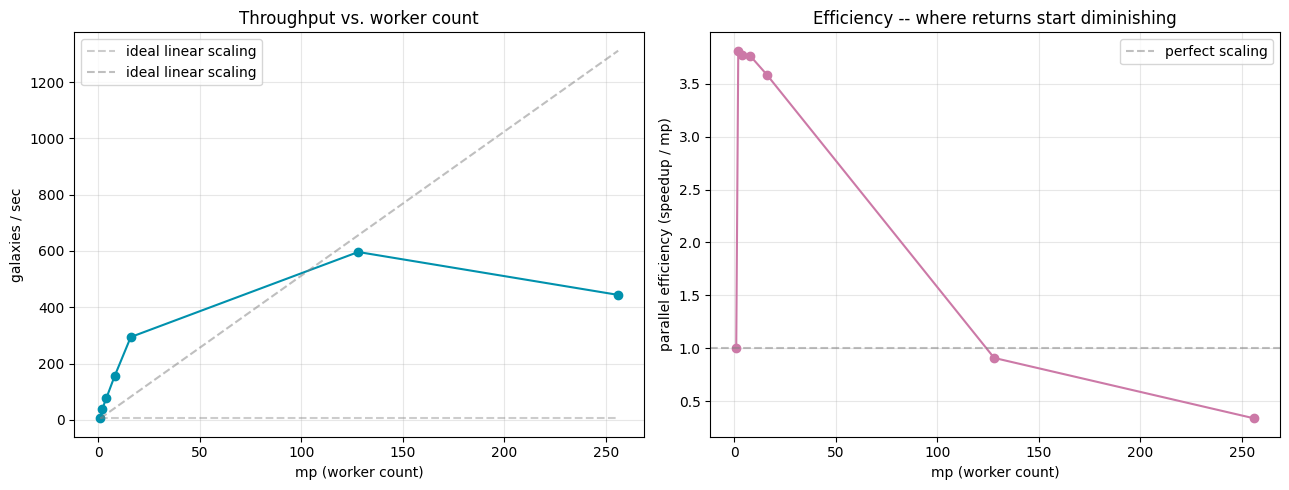

Highest raw throughput: mp=128 (596.3 gal/s)
Best mp at >=70% parallel efficiency: mp=128 (596.3 gal/s, 91% efficient)


In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(mp_df["mp"], mp_df["galaxies_per_sec"], "o-", color="#0091ad")
ax1.plot(mp_df["mp"], mp_df["mp"].iloc[0] * mp_df["galaxies_per_sec"].iloc[0] / mp_df["mp"].iloc[0] * mp_df["mp"] / mp_df["mp"],
         "--", color="gray", alpha=0.4, label="ideal linear scaling")
ideal = mp_df["galaxies_per_sec"].iloc[0] * mp_df["mp"]
ax1.plot(mp_df["mp"], ideal, "--", color="gray", alpha=0.5, label="ideal linear scaling")
ax1.set_xlabel("mp (worker count)")
ax1.set_ylabel("galaxies / sec")
ax1.set_title("Throughput vs. worker count")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(mp_df["mp"], mp_df["efficiency"], "o-", color="#CC79A7")
ax2.axhline(1.0, linestyle="--", color="gray", alpha=0.5, label="perfect scaling")
ax2.set_xlabel("mp (worker count)")
ax2.set_ylabel("parallel efficiency (speedup / mp)")
ax2.set_title("Efficiency -- where returns start diminishing")
ax2.legend()
ax2.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "mp_sweep.png", dpi=150)
plt.show()

best_throughput = mp_df.loc[mp_df["galaxies_per_sec"].idxmax()]
# "knee" pick: highest mp still above e.g. 70% efficiency -- usually the
# sweet spot, since raw-max-throughput configs often waste cores for a
# marginal gain not worth the contention/queueing cost on a shared filesystem
efficient = mp_df[mp_df["efficiency"] >= 0.7]
best_efficient = efficient.loc[efficient["mp"].idxmax()] if len(efficient) else best_throughput

print(f"Highest raw throughput: mp={int(best_throughput['mp'])} "
     f"({best_throughput['galaxies_per_sec']:.1f} gal/s)")
print(f"Best mp at >=70% parallel efficiency: mp={int(best_efficient['mp'])} "
     f"({best_efficient['galaxies_per_sec']:.1f} gal/s, "
     f"{best_efficient['efficiency']:.0%} efficient)")

In [48]:
print("\n" + "=" * 60)
print("CHUNKSIZE CHECK: confirm no speed effect, measure memory scaling")
print("=" * 60)

import resource

CHUNKSIZE_GRID = [500, 1000, 2000]
best_mp = int(best_efficient["mp"])
chunk_results = []

for cs in CHUNKSIZE_GRID:
    sub_args = bench_args[:cs] if cs <= len(bench_args) else bench_args
    mem_before = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss  # KB on Linux
    result = run_mp_benchmark(sub_args, best_mp, label=f"chunksize_check")
    mem_after = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    result["chunksize"] = cs
    result["peak_rss_mb_delta"] = (mem_after - mem_before) / 1024
    chunk_results.append(result)
    print(f"  chunksize={cs:>6,d}: {result['galaxies_per_sec']:.1f} gal/s, "
         f"RSS delta ~{result['peak_rss_mb_delta']:.0f} MB")

chunk_df = pd.DataFrame(chunk_results)
print("\nRate should be roughly flat across chunksize (it only governs output-file "
     "batching, per module docstring) -- if it varies a lot, something else is going on.")
print("\n" + "=" * 60)
print("RECOMMENDATION")
print("=" * 60)

recommended_mp = int(best_efficient["mp"])
recommended_rate = best_efficient["galaxies_per_sec"]
full_catalog_hours = len(sample) / recommended_rate / 3600

print(f"Recommended mp: {recommended_mp}")
print(f"  (chosen as the largest mp still at >=70% parallel efficiency, "
     f"avoiding wasted allocation on marginal returns / filesystem contention)")
print(f"Expected throughput: {recommended_rate:.1f} galaxies/sec")
print(f"Estimated full-catalog time ({len(sample):,d} galaxies): {full_catalog_hours:.1f} hours")
print(f"\nSuggested command:")
print(f"  python build_cutouts_fast.py \\")
print(f"      --catalog {CATALOG_PATH} \\")
print(f"      --region {REGION} \\")
print(f"      --outdir <your outdir> \\")
print(f"      --width {WIDTH} --pixscale {PIXSCALE} \\")
print(f"      --chunksize 50000 --mp {recommended_mp}")

if slurm_cpus and recommended_mp > int(slurm_cpus):
    print(f"\nWARNING: recommended mp ({recommended_mp}) exceeds your Slurm allocation "
         f"(SLURM_CPUS_PER_TASK={slurm_cpus}) -- cap at {slurm_cpus} or request more cores.")


CHUNKSIZE CHECK: confirm no speed effect, measure memory scaling
  chunksize=   500: 163.9 gal/s, RSS delta ~0 MB
  chunksize= 1,000: 361.9 gal/s, RSS delta ~0 MB
  chunksize= 2,000: 555.5 gal/s, RSS delta ~0 MB

Rate should be roughly flat across chunksize (it only governs output-file batching, per module docstring) -- if it varies a lot, something else is going on.

RECOMMENDATION
Recommended mp: 128
  (chosen as the largest mp still at >=70% parallel efficiency, avoiding wasted allocation on marginal returns / filesystem contention)
Expected throughput: 596.3 galaxies/sec
Estimated full-catalog time (470,625 galaxies): 0.2 hours

Suggested command:
  python build_cutouts_fast.py \
      --catalog /global/cfs/cdirs/desi/users/ioannis/SGA/2025/public/SGA2025-v1.0.fits \
      --region dr11-south \
      --outdir <your outdir> \
      --width 152 --pixscale 0.262 \
      --chunksize 50000 --mp 128
